Dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0    

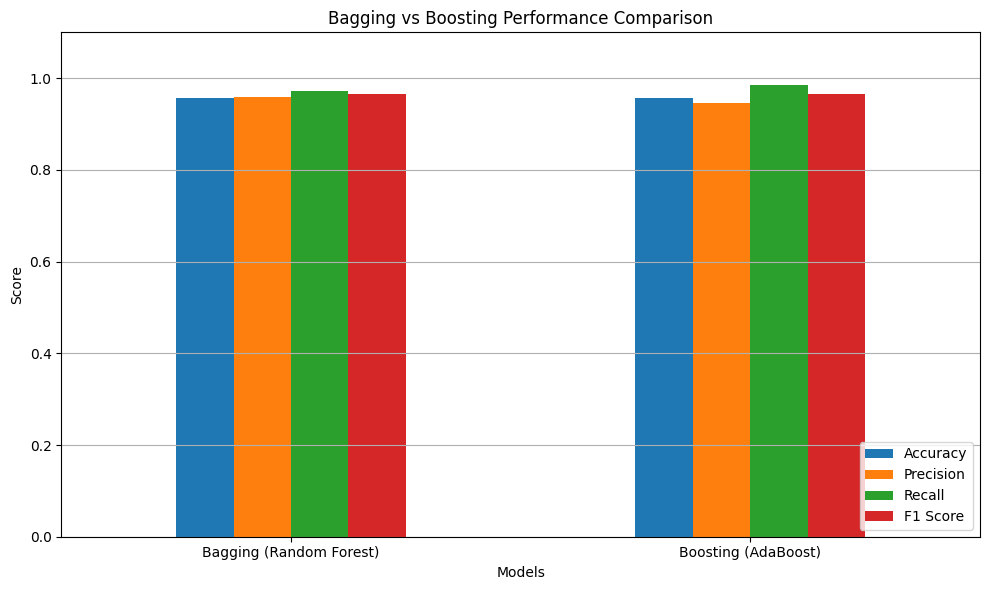

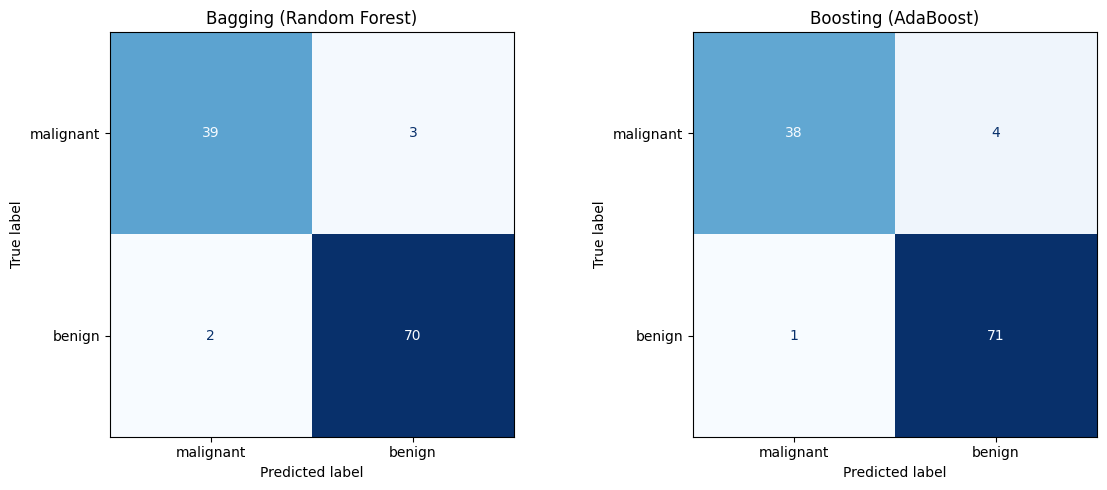

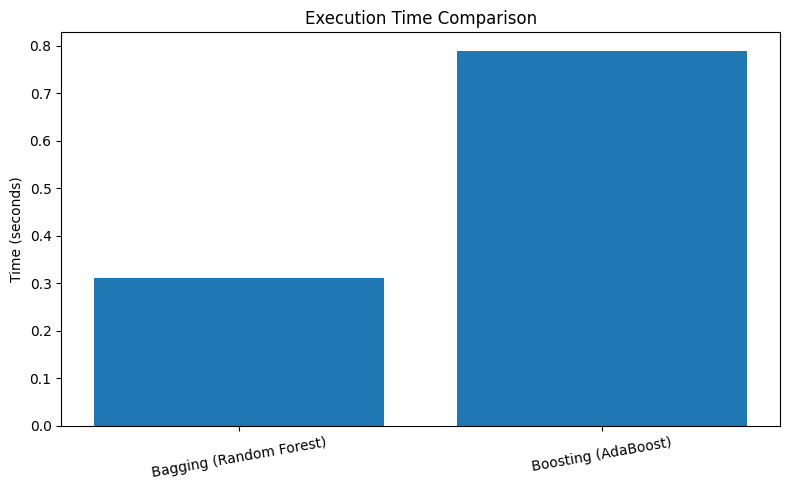

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Load Dataset
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

print("Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nClass Distribution:")
print(df['target'].value_counts())

# 2. Separate Features and Target
X = df.drop('target', axis=1)
y = df['target']

# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Create Models
models = {
    "Bagging (Random Forest)": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Boosting (AdaBoost)": AdaBoostClassifier(
        n_estimators=100, random_state=42
    )
}

results = []
predictions = {}

# 5. Train and Evaluate Models
for name, model in models.items():

    start = time.time()

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    end = time.time()

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'Time (seconds)': end - start
    })

    print("\n", name)
    print(classification_report(
        y_test, y_pred, target_names=data.target_names
    ))

# 6. Compare Performance
results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
print(results_df.to_string(index=False))

# 7. Visualize Performance Comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

results_df.set_index('Model')[metrics].plot(
    kind='bar', figsize=(10, 6)
)

plt.title("Bagging vs Boosting Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Models")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# 8. Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=data.target_names
    )

    display.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

# 9. Execution Time Comparison
plt.figure(figsize=(8, 5))

plt.bar(
    results_df['Model'],
    results_df['Time (seconds)']
)

plt.title("Execution Time Comparison")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()
